In [12]:
import pandas as pd 

In [2]:
df = pd.read_csv('PM-internship.csv')

In [3]:
df.head(5)

,Candidate_ID,Qualification,Course,Specialization,Home_State_UT,Home_District,Preferred_Sector,Preferred_Area_Field,Location_Preference,Relevant_Experience_Years,Past_Participation,Rural_Aspirational_District_Flag,Social_Category,Reference_Internship_ID,Data_Origin,Generation_Seed,Experiment_Note
0,SIM-C-000001,Diploma,Civil Engineering,Electrical and Electronics Engineering,BIHAR,Gaya,"Oil, Gas & Energy",Operations Management,Any State,0.0,0,0,OBC,PMIS-2026-61012,SIMULATED_CANDIDATE_PROFILE,20261020,BASE_SIMULATED_RECORD
1,SIM-C-000002,12th,ANY,ANY,KARNATAKA,Tumakuru,banking and financial services,Sales & Marketing,Same District,0.0,0,1,OBC,PMIS-2026-55249,SIMULATED_CANDIDATE_PROFILE,20261020,BASE_SIMULATED_RECORD
2,SIM-C-000003,12th,ANY,ANY,TAMIL NADU,Tirunelveli,Banking and financial Services,Sales & Marketing,Any State,0.0,0,1,General,PMIS-2026-62238,SIMULATED_CANDIDATE_PROFILE,20261020,BASE_SIMULATED_RECORD
3,SIM-C-000004,12th,ANY,ANY,TAMIL NADU,Chennai,Banking and financial Services,Sales & Marketing,Any State,0.0,0,0,OBC,PMIS-2026-62090,SIMULATED_CANDIDATE_PROFILE,20261020,BASE_SIMULATED_RECORD
4,SIM-C-000005,Graduation,B.Tech/B.E.,Electrical and Electronics Engineering,MAHARASHTRA,Palghar,"Oil, Gas & Energy",Operations Management,Same State,0.0,0,0,SC,PMIS-2026-61410,SIMULATED_CANDIDATE_PROFILE,20261020,BASE_SIMULATED_RECORD


In [5]:

import pandas as pd
import numpy as np
from pathlib import Path

# File paths
candidate_file = Path("PM-internship.csv")
match_file = Path(
    "PMIS_Expanded_50k_Simulated_Candidates-Simulated_Match_Pairs.csv"
)

# Load only the first 50,000 rows from each CSV
candidates = pd.read_csv(
    candidate_file,
    nrows=50000,
    low_memory=False
)

match_pairs = pd.read_csv(
    match_file,
    nrows=50000,
    low_memory=False
)

print("Candidate dataset shape:", candidates.shape)
print("Match-pairs dataset shape:", match_pairs.shape)

print("\nCandidate columns:")
print(candidates.columns.tolist())

print("\nMatch-pairs columns:")
print(match_pairs.columns.tolist())


Candidate dataset shape: (50000, 17)
Match-pairs dataset shape: (50000, 16)

Candidate columns:
['    Candidate_ID', 'Qualification', 'Course', 'Specialization', 'Home_State_UT', 'Home_District', 'Preferred_Sector', 'Preferred_Area_Field', 'Location_Preference', 'Relevant_Experience_Years', 'Past_Participation', 'Rural_Aspirational_District_Flag', 'Social_Category', 'Reference_Internship_ID', 'Data_Origin', 'Generation_Seed', 'Experiment_Note']

Match-pairs columns:
['Candidate_ID', 'Internship_ID', 'Qualification_Match', 'Course_Match', 'Specialization_Match', 'State_Match', 'District_Match', 'Sector_Match', 'Area_Field_Match', 'Location_Preference_Score', 'Internship_Opportunities_Official', 'Applications_Received_Official', 'Demand_Capacity_Ratio', 'Synthetic_Proxy_Match_Score', 'Synthetic_Proxy_Label', 'Label_Provenance']


In [6]:
match_pairs.head(5)

,Candidate_ID,Internship_ID,Qualification_Match,Course_Match,Specialization_Match,State_Match,District_Match,Sector_Match,Area_Field_Match,Location_Preference_Score,Internship_Opportunities_Official,Applications_Received_Official,Demand_Capacity_Ratio,Synthetic_Proxy_Match_Score,Synthetic_Proxy_Label,Label_Provenance
0,SIM-C-000001,PMIS-2026-58983,0,0,0,0,0,1,1,1,1,1,1.0000,0.4260,0,SIMULATED_HEURISTIC_NOT_REAL_SELECTION_OUTCOME
1,SIM-C-000002,PMIS-2026-61016,0,1,1,0,0,0,0,0,3,2,0.6667,0.2557,0,SIMULATED_HEURISTIC_NOT_REAL_SELECTION_OUTCOME
2,SIM-C-000003,PMIS-2026-61666,0,0,0,0,0,0,0,1,1,0,0.0000,0.1083,0,SIMULATED_HEURISTIC_NOT_REAL_SELECTION_OUTCOME
3,SIM-C-000004,PMIS-2026-60463,0,1,0,0,0,0,0,1,5,0,0.0000,0.3381,0,SIMULATED_HEURISTIC_NOT_REAL_SELECTION_OUTCOME
4,SIM-C-000005,PMIS-2026-59517,0,0,0,0,0,0,0,0,5,3,0.6000,0.1811,0,SIMULATED_HEURISTIC_NOT_REAL_SELECTION_OUTCOME


In [7]:

import pandas as pd
import numpy as np

# Reload the first 50,000 rows from each file
candidates = pd.read_csv(
    "PM-internship.csv",
    nrows=50000,
    low_memory=False
)

match_pairs = pd.read_csv(
    "PMIS_Expanded_50k_Simulated_Candidates-Simulated_Match_Pairs.csv",
    nrows=50000,
    low_memory=False
)

# Remove accidental spaces from column names and ID values
candidates.columns = candidates.columns.str.strip()
match_pairs.columns = match_pairs.columns.str.strip()

candidates["Candidate_ID"] = (
    candidates["Candidate_ID"].astype("string").str.strip()
)
match_pairs["Candidate_ID"] = (
    match_pairs["Candidate_ID"].astype("string").str.strip()
)

match_pairs["Internship_ID"] = (
    match_pairs["Internship_ID"].astype("string").str.strip()
)

# Remove duplicate candidate profiles and duplicate pairs
candidates = candidates.drop_duplicates(
    subset=["Candidate_ID"],
    keep="first"
)

match_pairs = match_pairs.drop_duplicates(
    subset=["Candidate_ID", "Internship_ID"],
    keep="first"
)

# Combine using Candidate_ID, not row position
data = match_pairs.merge(
    candidates,
    on="Candidate_ID",
    how="inner",
    validate="many_to_one",
    suffixes=("_match", "_candidate")
)

print("Candidate profiles:", candidates.shape)
print("Match pairs:", match_pairs.shape)
print("Combined dataset:", data.shape)

print("\nMissing target values:",
      data["Synthetic_Proxy_Label"].isna().sum())

display(data.head())


Candidate profiles: (50000, 17)
Match pairs: (50000, 16)
Combined dataset: (50000, 32)

Missing target values: 0


,Candidate_ID,Internship_ID,Qualification_Match,Course_Match,Specialization_Match,State_Match,District_Match,Sector_Match,Area_Field_Match,Location_Preference_Score,...,Preferred_Area_Field,Location_Preference,Relevant_Experience_Years,Past_Participation,Rural_Aspirational_District_Flag,Social_Category,Reference_Internship_ID,Data_Origin,Generation_Seed,Experiment_Note
0,SIM-C-000001,PMIS-2026-58983,0,0,0,0,0,1,1,1,...,Operations Management,Any State,0.0,0,0,OBC,PMIS-2026-61012,SIMULATED_CANDIDATE_PROFILE,20261020,BASE_SIMULATED_RECORD
1,SIM-C-000002,PMIS-2026-61016,0,1,1,0,0,0,0,0,...,Sales & Marketing,Same District,0.0,0,1,OBC,PMIS-2026-55249,SIMULATED_CANDIDATE_PROFILE,20261020,BASE_SIMULATED_RECORD
2,SIM-C-000003,PMIS-2026-61666,0,0,0,0,0,0,0,1,...,Sales & Marketing,Any State,0.0,0,1,General,PMIS-2026-62238,SIMULATED_CANDIDATE_PROFILE,20261020,BASE_SIMULATED_RECORD
3,SIM-C-000004,PMIS-2026-60463,0,1,0,0,0,0,0,1,...,Sales & Marketing,Any State,0.0,0,0,OBC,PMIS-2026-62090,SIMULATED_CANDIDATE_PROFILE,20261020,BASE_SIMULATED_RECORD
4,SIM-C-000005,PMIS-2026-59517,0,0,0,0,0,0,0,0,...,Operations Management,Same State,0.0,0,0,SC,PMIS-2026-61410,SIMULATED_CANDIDATE_PROFILE,20261020,BASE_SIMULATED_RECORD


Dataset shape: (50000, 32)

Data types:
Candidate_ID                          string
Internship_ID                         string
Qualification_Match                    int64
Course_Match                           int64
Specialization_Match                   int64
State_Match                            int64
District_Match                         int64
Sector_Match                           int64
Area_Field_Match                       int64
Location_Preference_Score              int64
Internship_Opportunities_Official      int64
Applications_Received_Official         int64
Demand_Capacity_Ratio                float64
Synthetic_Proxy_Match_Score          float64
Synthetic_Proxy_Label                  int64
Label_Provenance                         str
Qualification                            str
Course                                   str
Specialization                           str
Home_State_UT                            str
Home_District                            str
Preferred_Secto

Specialization               3033
Preferred_Area_Field         2001
Relevant_Experience_Years    1296
Preferred_Sector             1216
Home_District                 719
dtype: int64


Exact duplicate rows: 0

Target distribution:
Synthetic_Proxy_Label
0    43947
1     6053
Name: count, dtype: int64

Target percentage:
Synthetic_Proxy_Label
0    87.89
1    12.11
Name: proportion, dtype: float64


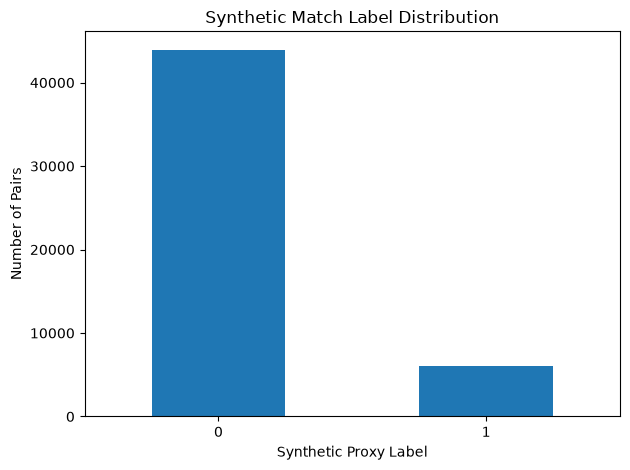

In [13]:

import matplotlib.pyplot as plt
import seaborn as sns

# Dataset overview
print("Dataset shape:", data.shape)
print("\nData types:")
print(data.dtypes)

print("\nMissing values:")
missing = data.isnull().sum().sort_values(ascending=False)
display(missing[missing > 0])

print("\nExact duplicate rows:", data.duplicated().sum())

# Target distribution
print("\nTarget distribution:")
print(data["Synthetic_Proxy_Label"].value_counts())

print("\nTarget percentage:")
print(
    (data["Synthetic_Proxy_Label"]
     .value_counts(normalize=True) * 100).round(2)
)

data["Synthetic_Proxy_Label"].value_counts().sort_index().plot(
    kind="bar",
    rot=0
)
plt.title("Synthetic Match Label Distribution")
plt.xlabel("Synthetic Proxy Label")
plt.ylabel("Number of Pairs")
plt.tight_layout()
plt.show()


In [14]:

# Missing-value percentages
missing_summary = pd.DataFrame({
    "Missing_Count": data.isnull().sum(),
    "Missing_Percentage": (
        data.isnull().mean() * 100
    ).round(2)
})

display(
    missing_summary[missing_summary["Missing_Count"] > 0]
    .sort_values("Missing_Percentage", ascending=False)
)

# Duplicate candidate-internship pairs
print(
    "Duplicate candidate-internship pairs:",
    data.duplicated(
        subset=["Candidate_ID", "Internship_ID"]
    ).sum()
)

# Confirm target balance
print("\nTarget counts:")
print(data["Synthetic_Proxy_Label"].value_counts())


,Missing_Count,Missing_Percentage
Specialization,3033,6.07
Preferred_Area_Field,2001,4.00
Relevant_Experience_Years,1296,2.59
Preferred_Sector,1216,2.43
Home_District,719,1.44


Duplicate candidate-internship pairs: 0

Target counts:
Synthetic_Proxy_Label
0    43947
1     6053
Name: count, dtype: int64


In [15]:

target_column = "Synthetic_Proxy_Label"

# Ensure the target is complete and binary
data = data.dropna(subset=[target_column]).copy()

data[target_column] = pd.to_numeric(
    data[target_column],
    errors="coerce"
)

data = data.dropna(subset=[target_column]).copy()
data[target_column] = data[target_column].astype(int)

if not set(data[target_column].unique()).issubset({0, 1}):
    raise ValueError("Target must contain only 0 and 1.")

# Preserve candidate IDs for grouped splitting
groups = data["Candidate_ID"].copy()

y = data[target_column].copy()

columns_to_drop = [
    "Candidate_ID",
    "Internship_ID",
    "Synthetic_Proxy_Label",
    "Synthetic_Proxy_Match_Score",
    "Label_Provenance",
    "Data_Origin",
    "Generation_Seed",
    "Experiment_Note",
    "Reference_Internship_ID"
]

X = data.drop(
    columns=columns_to_drop,
    errors="ignore"
)

# Remove constant columns
constant_columns = [
    column for column in X.columns
    if X[column].nunique(dropna=False) <= 1
]

X = X.drop(columns=constant_columns)

print("Feature matrix:", X.shape)
print("Target distribution:")
print(y.value_counts(normalize=True).round(3))

print("\nFeature columns:")
print(X.columns.tolist())


Feature matrix: (50000, 23)
Target distribution:
Synthetic_Proxy_Label
0    0.879
1    0.121
Name: proportion, dtype: float64

Feature columns:
['Qualification_Match', 'Course_Match', 'Specialization_Match', 'State_Match', 'District_Match', 'Sector_Match', 'Area_Field_Match', 'Location_Preference_Score', 'Internship_Opportunities_Official', 'Applications_Received_Official', 'Demand_Capacity_Ratio', 'Qualification', 'Course', 'Specialization', 'Home_State_UT', 'Home_District', 'Preferred_Sector', 'Preferred_Area_Field', 'Location_Preference', 'Relevant_Experience_Years', 'Past_Participation', 'Rural_Aspirational_District_Flag', 'Social_Category']


In [16]:

from sklearn.model_selection import GroupShuffleSplit

# Create an 80:20 train-test split by candidate
splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=42
)

train_idx, test_idx = next(
    splitter.split(X, y, groups=groups)
)

# Split features
X_train = X.iloc[train_idx].copy()
X_test = X.iloc[test_idx].copy()

# Split target
y_train = y.iloc[train_idx].copy()
y_test = y.iloc[test_idx].copy()

# Verify the split
print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("\nTraining target distribution:")
print(y_train.value_counts())

print("\nTesting target distribution:")
print(y_test.value_counts())

# Check for candidate overlap
train_candidates = set(groups.iloc[train_idx])
test_candidates = set(groups.iloc[test_idx])

print(
    "\nCandidates shared between train and test:",
    len(train_candidates.intersection(test_candidates))
)


Training features: (40000, 23)
Testing features: (10000, 23)

Training target distribution:
Synthetic_Proxy_Label
0    35208
1     4792
Name: count, dtype: int64

Testing target distribution:
Synthetic_Proxy_Label
0    8739
1    1261
Name: count, dtype: int64

Candidates shared between train and test: 0


In [17]:

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# Identify numeric and categorical columns using training data only
numeric_columns = X_train.select_dtypes(
    include=["number", "bool"]
).columns.tolist()

categorical_columns = X_train.select_dtypes(
    include=["object", "string", "category"]
).columns.tolist()

print("Number of numeric features:", len(numeric_columns))
print("Number of categorical features:", len(categorical_columns))

# Numeric preprocessing:
# Fill missing values with the median and scale the features
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Categorical preprocessing:
# Fill missing values and convert categories into numeric columns
categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Combine both preprocessing pipelines
preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_columns),
    ("categorical", categorical_pipeline, categorical_columns)
])

print("\nStep 4 preprocessing pipeline created successfully.")


Number of numeric features: 14
Number of categorical features: 9

Step 4 preprocessing pipeline created successfully.


In [18]:

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

# Model 1: Logistic Regression
logistic_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(
        max_iter=2000,
        class_weight="balanced",
        random_state=42
    ))
])

# Model 2: Random Forest
random_forest_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=200,
        max_depth=15,
        min_samples_leaf=2,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ))
])

# Train Logistic Regression
logistic_model.fit(X_train, y_train)
print("Logistic Regression training completed.")

# Train Random Forest
random_forest_model.fit(X_train, y_train)
print("Random Forest training completed.")


Logistic Regression training completed.
Random Forest training completed.



Logistic Regression
              precision    recall  f1-score   support

Negative (0)       1.00      0.95      0.97      8739
Positive (1)       0.73      0.98      0.84      1261

    accuracy                           0.95     10000
   macro avg       0.86      0.96      0.90     10000
weighted avg       0.96      0.95      0.96     10000



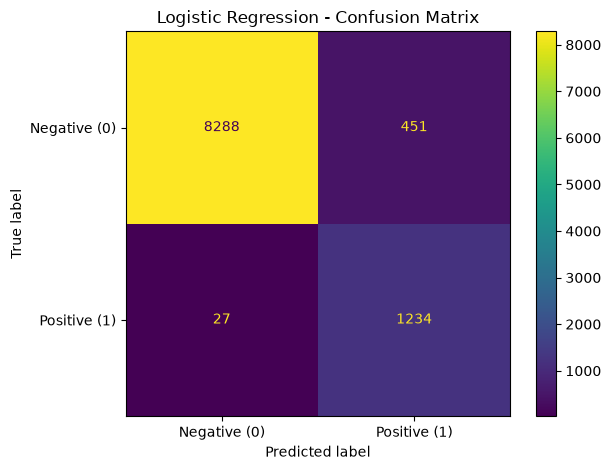


Random Forest
              precision    recall  f1-score   support

Negative (0)       1.00      0.93      0.96      8739
Positive (1)       0.68      0.98      0.80      1261

    accuracy                           0.94     10000
   macro avg       0.84      0.96      0.88     10000
weighted avg       0.96      0.94      0.94     10000



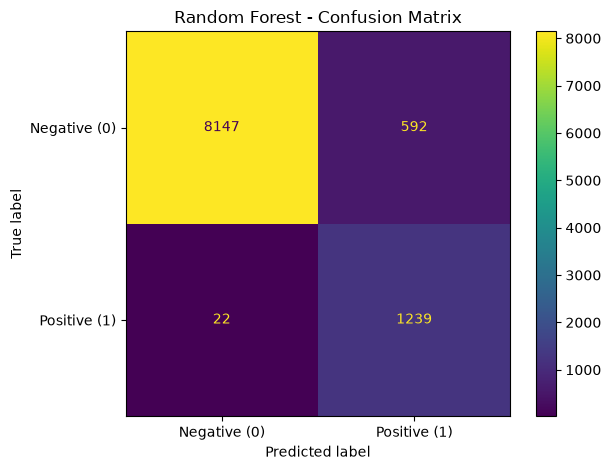


MODEL COMPARISON


,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Logistic Regression,0.9522,0.7323,0.9786,0.8377,0.9932
1,Random Forest,0.9386,0.6767,0.9826,0.8014,0.9904


In [19]:

import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    ConfusionMatrixDisplay
)

# Store both trained models
models = {
    "Logistic Regression": logistic_model,
    "Random Forest": random_forest_model
}

results = []

for model_name, model in models.items():

    # Predict labels and positive-class probabilities
    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1]

    # Calculate evaluation metrics
    accuracy = accuracy_score(y_test, y_pred)

    precision = precision_score(
        y_test, y_pred, zero_division=0
    )

    recall = recall_score(
        y_test, y_pred, zero_division=0
    )

    f1 = f1_score(
        y_test, y_pred, zero_division=0
    )

    roc_auc = roc_auc_score(y_test, y_prob)

    results.append({
        "Model": model_name,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1 Score": f1,
        "ROC-AUC": roc_auc
    })

    # Display detailed metrics
    print("\n" + "=" * 55)
    print(model_name)
    print("=" * 55)

    print(
        classification_report(
            y_test,
            y_pred,
            labels=[0, 1],
            target_names=["Negative (0)", "Positive (1)"],
            zero_division=0
        )
    )

    # Plot the confusion matrix
    ConfusionMatrixDisplay.from_predictions(
        y_test,
        y_pred,
        labels=[0, 1],
        display_labels=["Negative (0)", "Positive (1)"],
        values_format="d"
    )

    plt.title(f"{model_name} - Confusion Matrix")
    plt.tight_layout()
    plt.show()

# Create a comparison table
results_df = pd.DataFrame(results)

print("\nMODEL COMPARISON")
display(results_df.round(4))


In [20]:

# Check how strongly each numeric feature relates to the target
numeric_audit = X.copy()

numeric_audit["Target"] = y

correlations = (
    numeric_audit
    .select_dtypes(include="number")
    .corr()["Target"]
    .drop("Target")
    .sort_values(key=abs, ascending=False)
)

print("Numeric feature correlations with target:")
display(correlations.to_frame("Correlation").round(4))

# Check positive-label rates for matching indicators
match_columns = [
    "Qualification_Match",
    "Course_Match",
    "Specialization_Match",
    "State_Match",
    "District_Match",
    "Sector_Match",
    "Area_Field_Match"
]

for column in match_columns:
    if column in X.columns:
        print(f"\nPositive-label rate by {column}:")
        display(
            data.groupby(column, dropna=False)[
                "Synthetic_Proxy_Label"
            ].agg(["count", "mean"]).round(4)
        )


Numeric feature correlations with target:


,Correlation
Course_Match,0.6372
Qualification_Match,0.5679
Sector_Match,0.3796
Area_Field_Match,0.3342
Specialization_Match,0.1821
State_Match,0.1630
Location_Preference_Score,0.1051
District_Match,0.0830
Demand_Capacity_Ratio,-0.0424
Applications_Received_Official,-0.0320



Positive-label rate by Qualification_Match:


,count,mean
Qualification_Match,,
0,37775,0.0157
1,12225,0.4467



Positive-label rate by Course_Match:


...

,count,mean
District_Match,,
0,49651,0.1188
1,349,0.4441



Positive-label rate by Sector_Match:


,count,mean
Sector_Match,,
0,35403,0.0416
1,14597,0.3139



Positive-label rate by Area_Field_Match:


,count,mean
Area_Field_Match,,
0,33738,0.0454
1,16262,0.2781


In [21]:

# Check whether the synthetic score is associated with the target
score_column = "Synthetic_Proxy_Match_Score"
target_column = "Synthetic_Proxy_Label"

print("Correlation between synthetic score and target:")
print(
    data[score_column].corr(data[target_column]).round(4)
)

# Compare average scores for each target class
print("\nScore statistics by target label:")
display(
    data.groupby(target_column)[score_column]
    .agg(["count", "mean", "median", "min", "max"])
    .round(4)
)

# Examine label rates across score ranges
data["Score_Band"] = pd.cut(
    data[score_column],
    bins=5,
    duplicates="drop"
)

print("\nPositive-label rate by score range:")
display(
    data.groupby("Score_Band", observed=True)[target_column]
    .agg(["count", "mean"])
    .round(4)
)

# Remove this temporary analysis column
data.drop(columns=["Score_Band"], inplace=True)


Correlation between synthetic score and target:
0.7619

Score statistics by target label:


,count,mean,median,min,max
Synthetic_Proxy_Label,,,,,
0,43947,0.1498,0.1158,0.00,0.49
1,6053,0.6419,0.6294,0.49,1.00



Positive-label rate by score range:


,count,mean
Score_Band,,
"(-0.001, 0.2]",29021,0.0000
"(0.2, 0.4]",11918,0.0000
"(0.4, 0.6]",5516,0.4547
"(0.6, 0.8]",2989,1.0000
"(0.8, 1.0]",556,1.0000


In [24]:

from sklearn.metrics import classification_report, confusion_matrix
import pandas as pd

# Step 1: Predict labels using Logistic Regression
y_pred = logistic_model.predict(X_test)

# Step 2: Predict positive-class probabilities
y_prob = logistic_model.predict_proba(X_test)[:, 1]

# Step 3: Evaluate the model
print("LOGISTIC REGRESSION - CLASSIFICATION REPORT")
print(classification_report(y_test, y_pred))

print("CONFUSION MATRIX")
print(confusion_matrix(y_test, y_pred))

# Step 4: Create the predictions DataFrame
predictions = X_test.copy()

predictions["Actual_Label"] = y_test.to_numpy()
predictions["Predicted_Label"] = y_pred
predictions["Positive_Class_Probability"] = y_prob

# Step 5: Display the first 10 predictions
display(predictions.head(10))

# Step 6: Save predictions to CSV
predictions.to_csv(
    "PMIS_test_predictions.csv",
    index=False
)

print("Predictions saved to PMIS_test_predictions.csv")


LOGISTIC REGRESSION - CLASSIFICATION REPORT
              precision    recall  f1-score   support

           0       1.00      0.95      0.97      8739
           1       0.73      0.98      0.84      1261

    accuracy                           0.95     10000
   macro avg       0.86      0.96      0.90     10000
weighted avg       0.96      0.95      0.96     10000

CONFUSION MATRIX
[[8288  451]
 [  27 1234]]


,Qualification_Match,Course_Match,Specialization_Match,State_Match,District_Match,Sector_Match,Area_Field_Match,Location_Preference_Score,Internship_Opportunities_Official,Applications_Received_Official,...,Preferred_Sector,Preferred_Area_Field,Location_Preference,Relevant_Experience_Years,Past_Participation,Rural_Aspirational_District_Flag,Social_Category,Actual_Label,Predicted_Label,Positive_Class_Probability
4,0,0,0,0,0,0,0,0,5,3,...,"Oil, Gas & Energy",Operations Management,Same State,0.0,0,0,SC,0,0,2.993467e-08
6,0,0,0,0,0,1,1,0,1,1,...,"Oil, Gas & Energy",Operations Management,Same State,0.0,0,0,EWS,0,0,6.514035e-03
7,0,0,0,0,0,0,0,0,50,3,...,"Oil, Gas & Energy",Operations Management,Same State,0.0,0,1,General,0,0,1.164618e-07
38,0,0,0,0,0,1,1,0,1,0,...,"Oil, Gas & Energy",Operations Management,Same State,1.0,0,1,General,0,0,4.240247e-03
40,0,0,0,0,0,0,0,1,1,1,...,Banking and financial Services,Sales & Marketing,Any State,0.0,0,0,General,0,0,9.697475e-07
49,0,1,0,0,0,0,0,0,30,1,...,Telecom,Sales & Marketing,Same State,0.0,0,0,EWS,0,0,1.639352e-04
61,1,1,0,0,0,0,1,1,50,2,...,Banking and financial Services,NaN,Any State,0.0,0,0,General,1,1,9.880711e-01
62,0,0,0,0,0,0,1,0,4,6,...,"Oil, Gas & Energy",Operations Management,Same State,0.0,0,1,General,0,0,1.988918e-06
70,0,0,0,0,0,0,0,0,1,1,...,NaN,Sales & Marketing,Same State,0.0,1,0,OBC,0,0,8.008294e-08
71,1,1,1,0,0,1,0,1,1,2,...,"Oil, Gas & Energy",Sales & Marketing,Any State,0.0,0,0,EWS,1,1,9.999860e-01


Predictions saved to PMIS_test_predictions.csv


In [25]:

import joblib

# Save the trained model
joblib.dump(logistic_model, "logistic_model.pkl")

print("Logistic Regression model saved successfully.")


Logistic Regression model saved successfully.
